## Training of the descriptors-only classifier and the embeddings-only classifier on the 2st level

In [ ]:
import os
from pathlib import Path
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from keras import layers, losses, optimizers, models, metrics, callbacks
from keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report
from tensorflow.keras.utils import register_keras_serializable
import keras_tuner
from keras_tuner import RandomSearch, Hyperband, BayesianOptimization

In [ ]:
desc_dim = 887
emb_dim = 1024
batch_size = 32
epoch = 100
dtype = tf.float32
current_dir = Path.cwd()
ptf_path = str(current_dir.parent / 'datasets/Second_Level/train_feat.npy')
pte_path = str(current_dir.parent / 'datasets/Second_Level/train_emb.npy')
pvf_path = str(current_dir.parent / 'datasets/Second_Level/valid_feat.npy')
pve_path = str(current_dir.parent / 'datasets/Second_Level/valid_emb.npy')
y_train_path = str(current_dir.parent / 'datasets/Second_Level/y_train.npy')
y_valid_path = str(current_dir.parent / 'datasets/Second_Level/y_valid.npy')
model_e_dir = str(current_dir.parent / 'models/Second_Level/untrained_embedding_model.keras')
model_d_dir = str(current_dir.parent / 'models/Second_Level/untrained_descriptores_model.keras')

In [ ]:
test_emb_dir = str(current_dir.parent / 'datasets/Second_Level/test_emb.npy')
test_feat_dir = str(current_dir.parent / 'datasets/Second_Level/test_feat.npy')
y_test_dir = str(current_dir.parent / 'datasets/Second_Level/y_test.npy')

In [3]:
def set_reproducibility(seed=42):
    # 1. Fijar semilla en Python core
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_reproducibility()
tf.keras.mixed_precision.set_global_policy('float64')

In [4]:
def reset_weigths(model: models.Model):
    for layer in model.layers:
        if hasattr(layer, 'kernel_initializer'):
            layer.kernel.assign(layer.kernel_initializer(shape=layer.kernel.shape, dtype=layer.kernel.dtype))
        if hasattr(layer, 'bias_initializer') and layer.use_bias:
            layer.bias.assign(layer.bias_initializer(shape=layer.bias.shape, dtype=layer.bias.dtype))
        if hasattr(layer, 'moving_mean'):
            layer.moving_mean.assign(tf.zeros_like(layer.moving_mean))
        if hasattr(layer, 'moving_variance'):
            layer.moving_variance.assign(tf.ones_like(layer.moving_variance))
def load_untrained_model(model_dir):
    model: models.Model = models.load_model(str(model_dir))
    reset_weigths(model)
    return model

### Embeddings-only classifier

In [5]:
X_train = np.load(pte_path)
X_valid = np.load(pve_path)
y_train = np.load(y_train_path)
y_valid = np.load(y_valid_path)
train_d = tf.data.Dataset.from_tensor_slices(
    (X_train.astype('float32'), y_train)
).batch(batch_size)
valid_d = tf.data.Dataset.from_tensor_slices(
    (X_valid.astype('float32'), y_valid)
).batch(batch_size)

In [6]:
model: models.Model = load_untrained_model(model_e_dir)
model.summary()

c:\Users\Victor\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 38 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "classifier_2l_embedding_only"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise_1                │ (None, 1024)           │             0 │
│ (GaussianNoise)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 704)            │       721,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 704)            │         2,816 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 704)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 704)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 352)            │       248,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 352)            │         1,408 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 176)            │        62,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 176)            │           704 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 176)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 176)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 88)             │        15,576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 88)             │           352 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 88)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 88)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 7)              │           623 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 7)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,154,823 (12.03 MB)

 Trainable params: 1,050,727 (4.01 MB)

 Non-trainable params: 2,640 (10.31 KB)

 Optimizer params: 2,101,456 (8.02 MB)

In [7]:
def build_model(hp) -> keras.Model:
    input_emb = layers.Input(shape=(emb_dim,), dtype=dtype)
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
    activation = hp.Choice('activation', values=['relu', 'swish', 'leaky_relu', 'elu'])
    l2_reg = hp.Float('l2_reg', min_value=1e-5, max_value=1e-2, sampling='log')
    noise_std = hp.Float('noise_std', min_value=0.01, max_value=0.1, step=0.03)

    noisy_emb = layers.GaussianNoise(noise_std)(input_emb)

    #y = input_emb
    y = noisy_emb
    units_e = hp.Int(f'emb_units_start', min_value=64, max_value=768, step=64)
    for i in range(hp.Int('emb_layers', 1, 5)):
        y = layers.Dense(units_e // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(y)
        y = layers.BatchNormalization()(y)
        y = layers.Activation(activation)(y)
        y = layers.Dropout(dropout_rate)(y)

    z = layers.Dense(7)(y)
    output = layers.Activation('softmax')(z)
    model = models.Model(input_emb, output, name='classifier_2l_embedding_only')
    learning_rate = hp.Float('learning_rate', min_value=1e-6, max_value=1e-3, sampling='log')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='categorical_crossentropy',
        metrics=[metrics.AUC(curve='ROC', multi_label=True), metrics.F1Score(average='macro')]
    )
    return model

tuner = Hyperband(
        build_model,
        objective = "val_loss",
        max_epochs=50,
        factor=3,
        seed=42,
        directory='tunning_SL',
        project_name='enzyme_embedding_branch'
    )
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best Hyperparameters:")
lr = 0.0001
for param in best_hp.values:
    print(f"{param}: {best_hp.get(param)}")
    if param == 'learning_rate':
        lr = best_hp.get(param)

Reloading Tuner from tunning_SL\enzyme_embedding_branch\tuner0.json
Best Hyperparameters:
dropout_rate: 0.1
activation: elu
l2_reg: 1.9016382411238237e-05
noise_std: 0.09999999999999999
emb_units_start: 704
emb_layers: 4
learning_rate: 0.0002194078224627792
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 2
tuner/round: 2
tuner/trial_id: 0067


#### Training process

In [ ]:
from typing import Any
class Classifier(keras.Model):
    def __init__(self, model: keras.Model, loss, **kwargs: Any) -> None:
        super(Classifier, self).__init__(**kwargs)
        self.model = model
        self.current_loss = loss
        self.total_loss_tracker = metrics.Mean(name="loss")
        self.auc_tracker = metrics.AUC(curve='ROC', multi_label=True)
        self.f1_tracker = metrics.F1Score(average='macro')
    
    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.auc_tracker,
            self.f1_tracker
        ]
    
    def call(self, inputs) -> Any:
        return self.model(inputs)
    
    def train_step(self, data):
        X, y = data
        with tf.GradientTape() as tape:
            pred = self(X)
            loss = self.current_loss(y, pred)
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.total_loss_tracker.update_state(loss)
        pre_ind = tf.argmax(pred, axis=-1)
        one_hot_preds = tf.one_hot(pre_ind, pred.shape[-1])
        self.auc_tracker.update_state(y, one_hot_preds)
        self.f1_tracker.update_state(y, one_hot_preds)

        return {m.name: m.result() for m in self.metrics}
    
    def test_step(self, data):
        X, y = data
        pred = self(X)
        loss = self.current_loss(y, pred)
        self.total_loss_tracker.update_state(loss)
        pre_ind = tf.argmax(pred, axis=-1)
        one_hot_preds = tf.one_hot(pre_ind, pred.shape[-1])
        self.auc_tracker.update_state(y, one_hot_preds)
        self.f1_tracker.update_state(y, one_hot_preds)
        return {m.name: m.result() for m in self.metrics}

def train(train_data: tf.data.Dataset, valid_data: tf.data.Dataset, model: models.Model) -> None:
    optimizer = optimizers.Adam(0.0001, clipnorm=1.0)
    loss = losses.categorical_crossentropy
    ea = callbacks.EarlyStopping(
        monitor='val_f1_score',
        mode='max',
        patience=5,
        restore_best_weights=True
    )
    logger = callbacks.CSVLogger(str(current_dir.parent / 'notebooks/history_2l_emb.csv'))
    """
    rlr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', 
        factor=0.5,
        patience=3, 
        min_lr=1e-6,
        verbose=1
    )
    """
    classifier = Classifier(model, loss)
    classifier.compile(optimizer)
    classifier.fit(train_data, batch_size=batch_size, epochs=epoch, callbacks=[ea, logger], validation_data=valid_data)
    classifier.model.save(str(current_dir.parent / 'models/Second_Level/embedding_model.keras'))
    print('Training process completed')

In [9]:
train(train_d, valid_d, model)

Epoch 1/100


4646/4646 ━━━━━━━━━━━━━━━━━━━━ 107s 22ms/step - auc: 0.6890 - f1_score: 0.5059 - loss: 1.1994 - val_auc: 0.7559 - val_f1_score: 0.6149 - val_loss: 0.9911
Epoch 2/100
4646/4646 ━━━━━━━━━━━━━━━━━━━━ 98s 21ms/step - auc: 0.7819 - f1_score: 0.6570 - loss: 0.8885 - val_auc: 0.8041 - val_f1_score: 0.6989 - val_loss: 0.8097
Epoch 3/100
4646/4646 ━━━━━━━━━━━━━━━━━━━━ 99s 21ms/step - auc: 0.8295 - f1_score: 0.7328 - loss: 0.7211 - val_auc: 0.8301 - val_f1_score: 0.7460 - val_loss: 0.7046
Epoch 4/100
4646/4646 ━━━━━━━━━━━━━━━━━━━━ 99s 21ms/step - auc: 0.8627 - f1_score: 0.7844 - loss: 0.6004 - val_auc: 0.8501 - val_f1_score: 0.7751 - val_loss: 0.6337
Epoch 5/100
4646/4646 ━━━━━━━━━━━━━━━━━━━━ 103s 22ms/step - auc: 0.8861 - f1_score: 0.8203 - loss: 0.5106 - val_auc: 0.8670 - val_f1_score: 0.7998 - val_loss: 0.5809
Epoch 6/100
4646/4646 ━━━━━━━━━━━━━━━━━━━━ 102s 22ms/step - auc: 0.9031 - f1_score: 0.8465 - loss: 0.4421 - val_auc: 0.8808 - val_f1_score: 0.8192 - val_loss: 0.5423
Epoch 7/100
4646/46

In [ ]:
model: models.Model = models.load_model(str(current_dir.parent / 'models/Second_Level/embedding_model.keras'))

In [5]:
X_train = np.load(pte_path)
X_valid = np.load(pve_path)
y_train = np.load(y_train_path)
y_valid = np.load(y_valid_path)

In [6]:
pred_train = model.predict(X_train)
pred_valid = model.predict(X_valid)
pred_t = (pred_train > 0.5).astype(int)
pred_v = (pred_valid > 0.5).astype(int)

4646/4646 ━━━━━━━━━━━━━━━━━━━━ 22s 5ms/step
581/581 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step


In [7]:
y_train = np.argmax(y_train, axis=1)
y_valid = np.argmax(y_valid, axis=1)
pred_t = np.argmax(pred_t, axis=1)
pred_v = np.argmax(pred_v, axis=1)

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
def plot_con_matrix(matrix, class_labels, title):  
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()

Precision train: 0.9644
Precision valid: 0.9257
Recall train: 0.9591
Recall valid: 0.9164
AUC train: 0.9985
AUC valid: 0.9876
F1-score train: 0.9615
F1-score valid: 0.9206
Clasification report train:
              precision    recall  f1-score   support

           0       0.91      0.95      0.93     18091
           1       0.96      0.97      0.97     54075
           2       0.98      0.95      0.96     27627
           3       0.97      0.94      0.96     15299
           4       0.98      0.94      0.96      9563
           5       0.97      0.98      0.97     18099
           6       0.98      0.98      0.98      5901

    accuracy                           0.96    148655
   macro avg       0.96      0.96      0.96    148655
weighted avg       0.96      0.96      0.96    148655

Clasification report valid:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      2262
           1       0.92      0.94      0.93      6760
           2

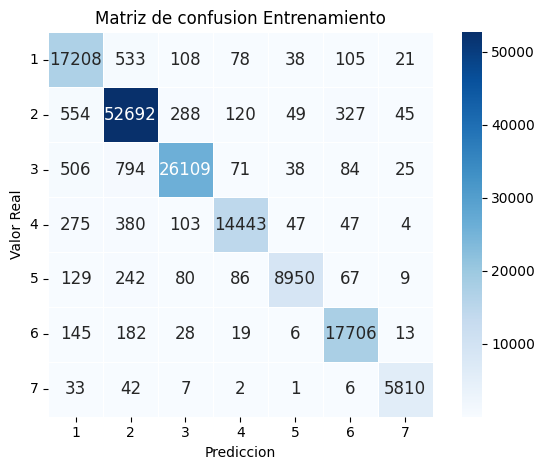

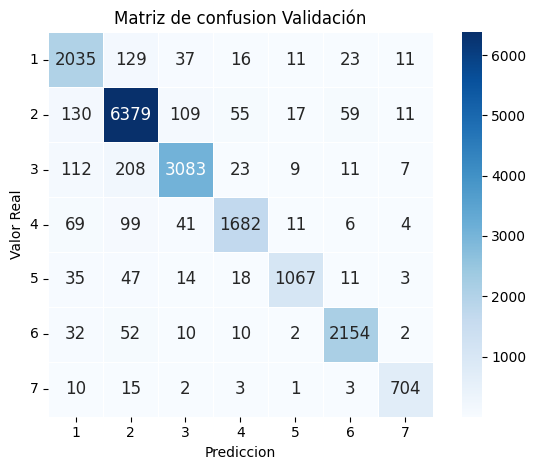

In [9]:
precision_t = precision_score(y_train, pred_t, average='macro')
precision_v = precision_score(y_valid, pred_v, average='macro')
recall_t = recall_score(y_train, pred_t, average='macro')
recall_v = recall_score(y_valid, pred_v, average='macro')
roc_auc_t = roc_auc_score(np.eye(7)[y_train], pred_train)
roc_auc_v = roc_auc_score(np.eye(7)[y_valid], pred_valid)
f1_t = f1_score(y_train, pred_t, average='macro')
f1_v = f1_score(y_valid, pred_v, average='macro')
conf_matrix_t = confusion_matrix(y_train, pred_t)
conf_matrix_v = confusion_matrix(y_valid, pred_v)
print(f"Precision train: {precision_t:.4f}")
print(f"Precision valid: {precision_v:.4f}")
print(f"Recall train: {recall_t:.4f}")
print(f"Recall valid: {recall_v:.4f}")
print(f'AUC train: {roc_auc_t:.4f}')
print(f'AUC valid: {roc_auc_v:.4f}')
print(f"F1-score train: {f1_t:.4f}")
print(f"F1-score valid: {f1_v:.4f}")
print("Clasification report train:", classification_report(y_train, pred_t), sep=f'\n')
print("Clasification report valid:", classification_report(y_valid, pred_v), sep=f'\n')
class_labels = [1, 2, 3, 4, 5, 6, 7]
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Entrenamiento')
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Validación')

581/581 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
F1-Score test: 0.9300
Clasification report test:
              precision    recall  f1-score   support

           0       0.87      0.91      0.89      2261
           1       0.93      0.95      0.94      6759
           2       0.94      0.91      0.92      3453
           3       0.95      0.90      0.92      1913
           4       0.96      0.90      0.93      1196
           5       0.95      0.95      0.95      2263
           6       0.96      0.96      0.96       737

    accuracy                           0.93     18582
   macro avg       0.93      0.93      0.93     18582
weighted avg       0.93      0.93      0.93     18582



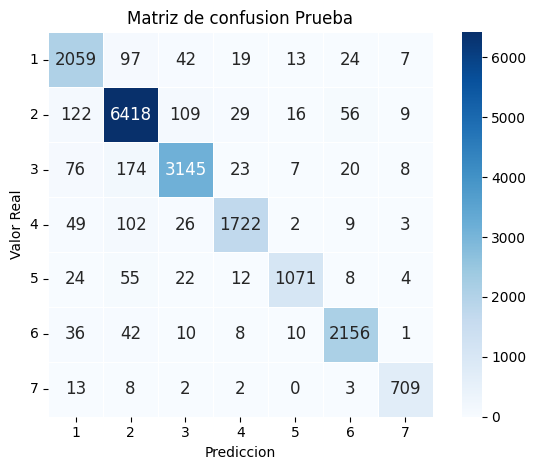

In [9]:
X_test = np.load(test_emb_dir)
y_test = np.load(y_test_dir)
pred_test = model.predict(X_test)
pred_test = (pred_test > 0.5).astype(int)
pred_test = np.argmax(pred_test, axis=1)
y_test = np.argmax(y_test, axis=1)
f1_t = f1_score(y_test, pred_test, average='macro')
conf_matrix_t = confusion_matrix(y_test, pred_test)
class_labels = [1, 2, 3, 4, 5, 6, 7]
print(f"F1-Score test: {f1_t:.4f}")
print("Clasification report test:", classification_report(y_test, pred_test), sep=f'\n')
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Prueba')

In [ ]:
history = pd.read_csv(str(current_dir.parent / 'notebooks/history_2l_emb.csv'))
history.head(27)

,epoch,auc,f1_score,loss,val_auc,val_f1_score,val_loss
0,0,0.688989,0.505856,1.199424,0.755874,0.614916,0.991073
1,1,0.781851,0.656956,0.888454,0.804138,0.698884,0.809736
2,2,0.829548,0.732752,0.721079,0.830140,0.746049,0.704568
3,3,0.862729,0.784400,0.600394,0.850070,0.775108,0.633709
4,4,0.886063,0.820321,0.510597,0.867030,0.799755,0.580937
5,5,0.903060,0.846450,0.442141,0.880812,0.819212,0.542340
6,6,0.916401,0.867404,0.388488,0.893053,0.837919,0.510690
7,7,0.926730,0.883601,0.345927,0.906004,0.856627,0.474577
8,8,0.934822,0.896292,0.311107,0.919889,0.875667,0.440034
9,9,0.941492,0.907044,0.283678,0.925932,0.882485,0.431438


In [11]:
from matplotlib.ticker import MaxNLocator
def plot_charts(history: pd.DataFrame, metrics: tuple[str, str], labels: tuple[str, str]):
    epochs = history['epoch'].to_numpy() + 1 if 'epoch' in history.columns else np.arange(1, len(history) + 1)

    best_val_loss_idx = history[f'val_{metrics[0]}'].idxmin()
    best_val_acc_idx = history[f'val_{metrics[1]}'].idxmax()

    train_color = '#1f77b4'
    valid_color = '#d62728'
    highlight_color = '#222222'

    sns.set_theme(style='whitegrid', context='paper')
    plt.rcParams.update({
        'font.size': 11,
        'axes.titlesize': 13,
        'axes.labelsize': 11,
        'legend.fontsize': 10,
        'xtick.labelsize': 10,
        'ytick.labelsize': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
    })

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180, constrained_layout=True)

    metric_specs = [
        {
            'ax': axes[0],
            'train_key': metrics[0],
            'valid_key': f'val_{metrics[0]}',
            'title': f'{labels[0]} del entrenamiento y validación',
            'ylabel': labels[0],
            'best_idx': best_val_loss_idx,
        },
        {
            'ax': axes[1],
            'train_key': metrics[1],
            'valid_key': f'val_{metrics[1]}',
            'title': f'{labels[1]} del entrenamiento y validación',
            'ylabel': labels[1],
            'best_idx': best_val_acc_idx,
        },
    ]

    for spec in metric_specs:
        ax = spec['ax']
        train_values = history[spec['train_key']].to_numpy()
        valid_values = history[spec['valid_key']].to_numpy()
        best_epoch = int(epochs[spec['best_idx']])
        best_value = valid_values[spec['best_idx']]

        ax.plot(epochs, train_values, color=train_color, lw=2.2, label='Entrenamiento')
        ax.plot(epochs, valid_values, color=valid_color, lw=2.2, ls='--', label='Validación')
        ax.scatter(best_epoch, best_value, color=highlight_color, s=38, zorder=5)
        ax.axvline(best_epoch, color=highlight_color, lw=1.0, ls=':', alpha=0.8)
        '''
        ax.annotate(
            f"Época {best_epoch}\n{best_value:.4f}",
            xy=(best_epoch, best_value),
            xytext=(10, 12),
            textcoords='offset points',
            fontsize=9,
            color=highlight_color,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#444444', alpha=0.95),
            arrowprops=dict(arrowstyle='->', color=highlight_color, lw=0.9),
        )
        '''

        ax.set_title(spec['title'], pad=10, weight='bold')
        ax.set_xlabel('Época')
        ax.set_ylabel(spec['ylabel'])
        ax.set_xlim(epochs.min(), epochs.max())
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(True, which='major', color='#d9d9d9', lw=0.8)
        ax.grid(True, which='minor', color='#efefef', lw=0.5, alpha=0.7)
        ax.minorticks_on()
        ax.tick_params(axis='both', which='major', length=5, width=0.8)
        ax.legend(loc='best', frameon=True, framealpha=0.95, edgecolor='#d0d0d0')

    axes[0].text(
        0.02,
        0.98,
        f"{labels[0]} final del entrenamiento: {history[metrics[0]].iloc[-1]:.4f}\n{labels[0]} final validación: {history[f'val_{metrics[0]}'].iloc[-1]:.4f}",
        transform=axes[0].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    axes[1].text(
        0.02,
        0.98,
        f"{labels[1]} final entrenamiento: {history[metrics[1]].iloc[-1]:.4f}\n{labels[1]} final validación: {history[f'val_{metrics[1]}'].iloc[-1]:.4f}",
        transform=axes[1].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    fig.suptitle('Curvas de aprendizaje del modelo', fontsize=15, weight='bold', y=1.03)
    sns.despine(fig=fig)
    plt.show()

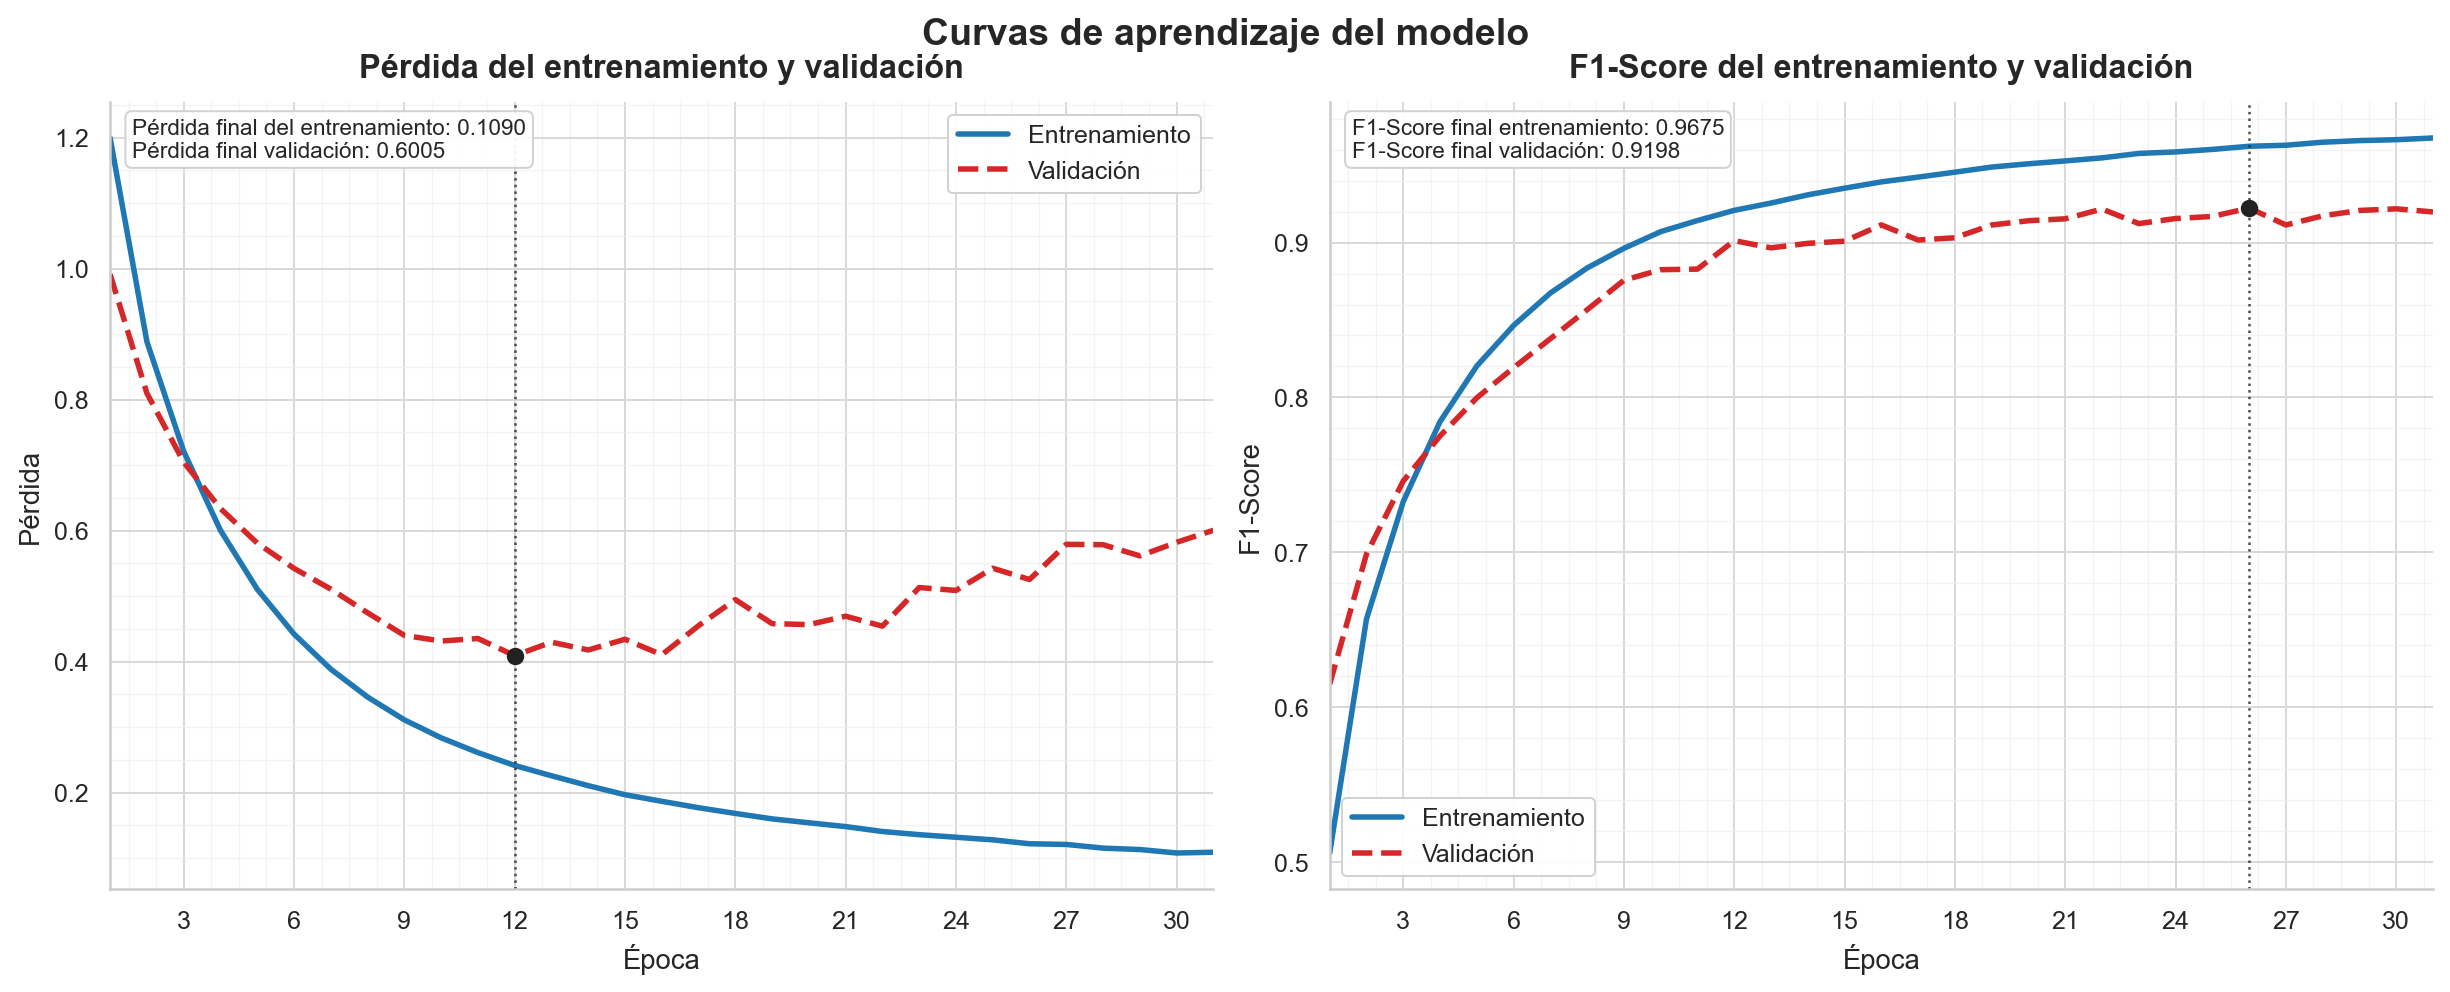

In [12]:
plot_charts(history, ('loss', 'f1_score'), ('Pérdida', 'F1-Score'))

### Descriptores-only classifier

In [5]:
X_train = np.load(ptf_path)
X_valid = np.load(pvf_path)
y_train = np.load(y_train_path)
y_valid = np.load(y_valid_path)
train_d = tf.data.Dataset.from_tensor_slices(
    (X_train.astype('float32'), y_train)
).batch(batch_size)
valid_d = tf.data.Dataset.from_tensor_slices(
    (X_valid.astype('float32'), y_valid)
).batch(batch_size)

In [7]:
model: models.Model = load_untrained_model(model_d_dir)
model.summary()

c:\Users\Victor\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "classifier_2l_descriptores_only"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 887)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise_1                │ (None, 887)            │             0 │
│ (GaussianNoise)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 320)            │       284,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 320)            │         1,280 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 160)            │        51,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 160)            │           640 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 160)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 160)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 7)              │         1,127 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 7)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,013,783 (3.87 MB)

 Trainable params: 337,607 (1.29 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 675,216 (2.58 MB)

In [8]:
def build_model(hp) -> keras.Model:
    input_desc = layers.Input(shape=(desc_dim,), dtype=dtype)
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
    activation = hp.Choice('activation', values=['relu', 'swish', 'leaky_relu', 'elu'])
    l2_reg = hp.Float('l2_reg', min_value=1e-5, max_value=1e-2, sampling='log')
    noise_std = hp.Float('noise_std', min_value=0.01, max_value=0.1, step=0.03)

    noisy_desc = layers.GaussianNoise(noise_std)(input_desc)

    #y = input_emb
    y = noisy_desc
    units_e = hp.Int(f'desc_units_start', min_value=64, max_value=768, step=64)
    for i in range(hp.Int('desc_layers', 1, 5)):
        y = layers.Dense(units_e // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(y)
        y = layers.BatchNormalization()(y)
        y = layers.Activation(activation)(y)
        y = layers.Dropout(dropout_rate)(y)

    z = layers.Dense(7)(y)
    output = layers.Activation('softmax')(z)
    model = models.Model(input_desc, output, name='classifier_2l_descriptores_only')
    learning_rate = hp.Float('learning_rate', min_value=1e-6, max_value=1e-3, sampling='log')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='categorical_crossentropy',
        metrics=[metrics.AUC(curve='ROC', multi_label=True), metrics.F1Score(average='macro')]
    )
    return model

tuner = Hyperband(
        build_model,
        objective = "val_loss",
        max_epochs=50,
        factor=3,
        seed=42,
        directory='tunning_SL',
        project_name='enzyme_descriptores_branch'
    )
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best Hyperparameters:")
lr = 0.0001
for param in best_hp.values:
    print(f"{param}: {best_hp.get(param)}")
    if param == 'learning_rate':
        lr = best_hp.get(param)

Reloading Tuner from tunning_SL\enzyme_descriptores_branch\tuner0.json
Best Hyperparameters:
dropout_rate: 0.30000000000000004
activation: relu
l2_reg: 6.725951483680074e-05
noise_std: 0.09999999999999999
desc_units_start: 320
desc_layers: 2
learning_rate: 0.0002338792801144213
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 3
tuner/round: 3
tuner/trial_id: 0047


#### Training process

In [ ]:
from typing import Any
class Classifier(keras.Model):
    def __init__(self, model: keras.Model, loss, **kwargs: Any) -> None:
        super(Classifier, self).__init__(**kwargs)
        self.model = model
        self.current_loss = loss
        self.total_loss_tracker = metrics.Mean(name="loss")
        self.auc_tracker = metrics.AUC(curve='ROC', multi_label=True)
        self.f1_tracker = metrics.F1Score(average='macro')
    
    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.auc_tracker,
            self.f1_tracker
        ]
    
    def call(self, inputs) -> Any:
        return self.model(inputs)
    
    def train_step(self, data):
        X, y = data
        with tf.GradientTape() as tape:
            pred = self(X)
            loss = self.current_loss(y, pred)
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.total_loss_tracker.update_state(loss)
        pre_ind = tf.argmax(pred, axis=-1)
        one_hot_preds = tf.one_hot(pre_ind, pred.shape[-1])
        self.auc_tracker.update_state(y, one_hot_preds)
        self.f1_tracker.update_state(y, one_hot_preds)

        return {m.name: m.result() for m in self.metrics}
    
    def test_step(self, data):
        X, y = data
        pred = self(X)
        loss = self.current_loss(y, pred)
        self.total_loss_tracker.update_state(loss)
        pre_ind = tf.argmax(pred, axis=-1)
        one_hot_preds = tf.one_hot(pre_ind, pred.shape[-1])
        self.auc_tracker.update_state(y, one_hot_preds)
        self.f1_tracker.update_state(y, one_hot_preds)
        return {m.name: m.result() for m in self.metrics}

def train(train_data: tf.data.Dataset, valid_data: tf.data.Dataset, model: models.Model) -> None:
    optimizer = optimizers.Adam(0.0001, clipnorm=1.0)
    loss = losses.binary_crossentropy
    ea = callbacks.EarlyStopping(
        monitor='val_f1_score',
        mode='max',
        patience=5,
        restore_best_weights=True
    )
    logger = callbacks.CSVLogger(str(current_dir.parent / 'notebooks/history_2l_feat.csv'))
    """
    rlr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', 
        factor=0.5,
        patience=3, 
        min_lr=1e-6,
        verbose=1
    )
    """
    classifier = Classifier(model, loss)
    classifier.compile(optimizer)
    classifier.fit(train_data, batch_size=batch_size, epochs=epoch, callbacks=[ea, logger], validation_data=valid_data)
    classifier.model.save(str(current_dir.parent / 'models/Second_Level/descriptores_model.keras'))
    print('Training process completed')

In [10]:
train(train_d, valid_d, model)

Epoch 1/100


4646/4646 ━━━━━━━━━━━━━━━━━━━━ 50s 10ms/step - auc: 0.7546 - f1_score: 0.6247 - loss: 0.2453 - val_auc: 0.8393 - val_f1_score: 0.7553 - val_loss: 0.1880
Epoch 2/100
4646/4646 ━━━━━━━━━━━━━━━━━━━━ 45s 10ms/step - auc: 0.8715 - f1_score: 0.8045 - loss: 0.1557 - val_auc: 0.8845 - val_f1_score: 0.8221 - val_loss: 0.1469
Epoch 3/100
4646/4646 ━━━━━━━━━━━━━━━━━━━━ 46s 10ms/step - auc: 0.9066 - f1_score: 0.8579 - loss: 0.1198 - val_auc: 0.9044 - val_f1_score: 0.8525 - val_loss: 0.1277
Epoch 4/100
4646/4646 ━━━━━━━━━━━━━━━━━━━━ 45s 10ms/step - auc: 0.9258 - f1_score: 0.8871 - loss: 0.0987 - val_auc: 0.9145 - val_f1_score: 0.8692 - val_loss: 0.1174
Epoch 5/100
4646/4646 ━━━━━━━━━━━━━━━━━━━━ 46s 10ms/step - auc: 0.9389 - f1_score: 0.9073 - loss: 0.0839 - val_auc: 0.9208 - val_f1_score: 0.8784 - val_loss: 0.1119
Epoch 6/100
4646/4646 ━━━━━━━━━━━━━━━━━━━━ 46s 10ms/step - auc: 0.9481 - f1_score: 0.9213 - loss: 0.0729 - val_auc: 0.9250 - val_f1_score: 0.8852 - val_loss: 0.1090
Epoch 7/100
4646/4646 

In [ ]:
model: models.Model = models.load_model(str(current_dir.parent / 'models/Second_Level/descriptores_model.keras'))

In [5]:
X_train = np.load(ptf_path)
X_valid = np.load(pvf_path)
y_train = np.load(y_train_path)
y_valid = np.load(y_valid_path)

In [6]:
pred_train = model.predict(X_train)
pred_valid = model.predict(X_valid)
pred_t = (pred_train > 0.5).astype(int)
pred_v = (pred_valid > 0.5).astype(int)

4646/4646 ━━━━━━━━━━━━━━━━━━━━ 14s 3ms/step
581/581 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step


In [7]:
y_train = np.argmax(y_train, axis=1)
y_valid = np.argmax(y_valid, axis=1)
pred_t = np.argmax(pred_t, axis=1)
pred_v = np.argmax(pred_v, axis=1)

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
def plot_con_matrix(matrix, class_labels, title):  
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()

Precision train: 0.9903
Precision valid: 0.9086
Recall train: 0.9875
Recall valid: 0.8970
AUC train: 0.9997
AUC valid: 0.9843
F1-score train: 0.9889
F1-score valid: 0.9025
Clasification report train:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98     18091
           1       0.99      0.99      0.99     54075
           2       0.99      0.98      0.98     27627
           3       0.99      0.99      0.99     15299
           4       0.99      0.98      0.99      9563
           5       0.99      0.99      0.99     18099
           6       1.00      0.99      1.00      5901

    accuracy                           0.99    148655
   macro avg       0.99      0.99      0.99    148655
weighted avg       0.99      0.99      0.99    148655

Clasification report valid:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      2262
           1       0.90      0.93      0.91      6760
           2

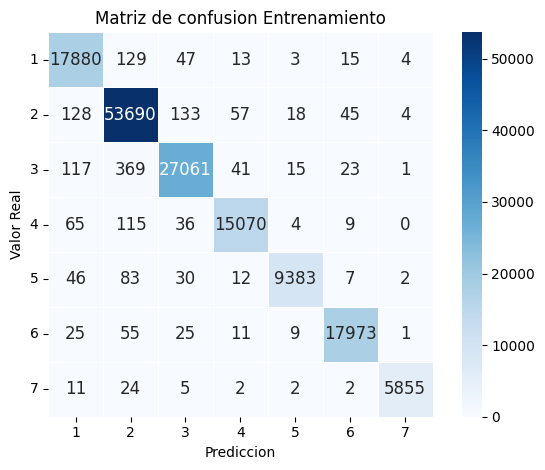

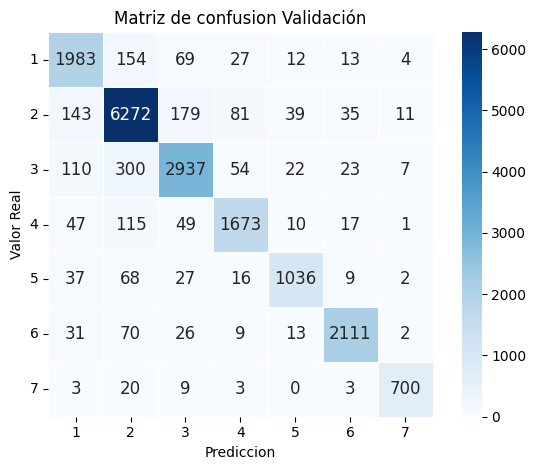

In [9]:
precision_t = precision_score(y_train, pred_t, average='macro')
precision_v = precision_score(y_valid, pred_v, average='macro')
recall_t = recall_score(y_train, pred_t, average='macro')
recall_v = recall_score(y_valid, pred_v, average='macro')
roc_auc_t = roc_auc_score(np.eye(7)[y_train], pred_train)
roc_auc_v = roc_auc_score(np.eye(7)[y_valid], pred_valid)
f1_t = f1_score(y_train, pred_t, average='macro')
f1_v = f1_score(y_valid, pred_v, average='macro')
conf_matrix_t = confusion_matrix(y_train, pred_t)
conf_matrix_v = confusion_matrix(y_valid, pred_v)
print(f"Precision train: {precision_t:.4f}")
print(f"Precision valid: {precision_v:.4f}")
print(f"Recall train: {recall_t:.4f}")
print(f"Recall valid: {recall_v:.4f}")
print(f'AUC train: {roc_auc_t:.4f}')
print(f'AUC valid: {roc_auc_v:.4f}')
print(f"F1-score train: {f1_t:.4f}")
print(f"F1-score valid: {f1_v:.4f}")
print("Clasification report train:", classification_report(y_train, pred_t), sep=f'\n')
print("Clasification report valid:", classification_report(y_valid, pred_v), sep=f'\n')
class_labels = [1, 2, 3, 4, 5, 6, 7]
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Entrenamiento')
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Validación')

581/581 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step
F1-Score test: 0.9064
Clasification report test:
              precision    recall  f1-score   support

           0       0.85      0.88      0.86      2261
           1       0.90      0.93      0.92      6759
           2       0.90      0.86      0.88      3453
           3       0.91      0.88      0.90      1913
           4       0.92      0.86      0.89      1196
           5       0.95      0.94      0.94      2263
           6       0.97      0.95      0.96       737

    accuracy                           0.90     18582
   macro avg       0.91      0.90      0.91     18582
weighted avg       0.90      0.90      0.90     18582



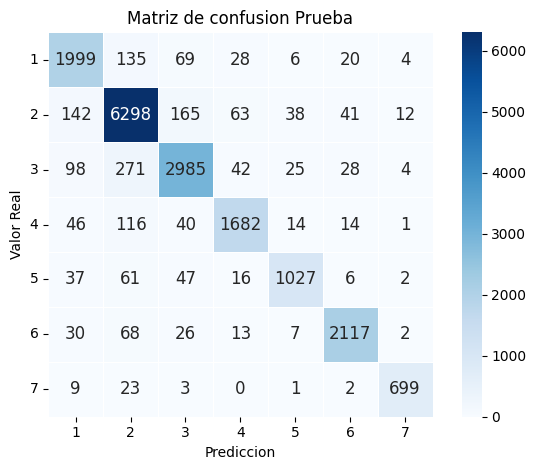

In [6]:
X_test = np.load(test_feat_dir)
y_test = np.load(y_test_dir)
pred_test = model.predict(X_test)
pred_test = (pred_test > 0.5).astype(int)
pred_test = np.argmax(pred_test, axis=1)
y_test = np.argmax(y_test, axis=1)
f1_t = f1_score(y_test, pred_test, average='macro')
conf_matrix_t = confusion_matrix(y_test, pred_test)
class_labels = [1, 2, 3, 4, 5, 6, 7]
print(f"F1-Score test: {f1_t:.4f}")
print("Clasification report test:", classification_report(y_test, pred_test), sep=f'\n')
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Prueba')

In [ ]:
history = pd.read_csv(str(current_dir.parent / 'notebooks/history_2l_feat.csv'))
history.head(29)

,epoch,auc,f1_score,loss,val_auc,val_f1_score,val_loss
0,0,0.754634,0.624689,0.245348,0.839320,0.755252,0.187991
1,1,0.871468,0.804473,0.155707,0.884534,0.822057,0.146860
2,2,0.906574,0.857861,0.119835,0.904402,0.852499,0.127743
3,3,0.925809,0.887111,0.098655,0.914515,0.869165,0.117438
4,4,0.938943,0.907277,0.083933,0.920834,0.878372,0.111917
5,5,0.948147,0.921349,0.072866,0.925010,0.885153,0.108955
6,6,0.955904,0.933152,0.063997,0.927640,0.888600,0.108153
7,7,0.962074,0.942465,0.056718,0.930645,0.892824,0.108789
8,8,0.966757,0.949685,0.050579,0.932280,0.894407,0.110429
9,9,0.971113,0.956194,0.045367,0.933177,0.895549,0.114118


In [11]:
from matplotlib.ticker import MaxNLocator
def plot_charts(history: pd.DataFrame, metrics: tuple[str, str], labels: tuple[str, str]):
    epochs = history['epoch'].to_numpy() + 1 if 'epoch' in history.columns else np.arange(1, len(history) + 1)

    best_val_loss_idx = history[f'val_{metrics[0]}'].idxmin()
    best_val_acc_idx = history[f'val_{metrics[1]}'].idxmax()

    train_color = '#1f77b4'
    valid_color = '#d62728'
    highlight_color = '#222222'

    sns.set_theme(style='whitegrid', context='paper')
    plt.rcParams.update({
        'font.size': 11,
        'axes.titlesize': 13,
        'axes.labelsize': 11,
        'legend.fontsize': 10,
        'xtick.labelsize': 10,
        'ytick.labelsize': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
    })

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180, constrained_layout=True)

    metric_specs = [
        {
            'ax': axes[0],
            'train_key': metrics[0],
            'valid_key': f'val_{metrics[0]}',
            'title': f'{labels[0]} del entrenamiento y validación',
            'ylabel': labels[0],
            'best_idx': best_val_loss_idx,
        },
        {
            'ax': axes[1],
            'train_key': metrics[1],
            'valid_key': f'val_{metrics[1]}',
            'title': f'{labels[1]} del entrenamiento y validación',
            'ylabel': labels[1],
            'best_idx': best_val_acc_idx,
        },
    ]

    for spec in metric_specs:
        ax = spec['ax']
        train_values = history[spec['train_key']].to_numpy()
        valid_values = history[spec['valid_key']].to_numpy()
        best_epoch = int(epochs[spec['best_idx']])
        best_value = valid_values[spec['best_idx']]

        ax.plot(epochs, train_values, color=train_color, lw=2.2, label='Entrenamiento')
        ax.plot(epochs, valid_values, color=valid_color, lw=2.2, ls='--', label='Validación')
        ax.scatter(best_epoch, best_value, color=highlight_color, s=38, zorder=5)
        ax.axvline(best_epoch, color=highlight_color, lw=1.0, ls=':', alpha=0.8)
        '''
        ax.annotate(
            f"Época {best_epoch}\n{best_value:.4f}",
            xy=(best_epoch, best_value),
            xytext=(10, 12),
            textcoords='offset points',
            fontsize=9,
            color=highlight_color,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#444444', alpha=0.95),
            arrowprops=dict(arrowstyle='->', color=highlight_color, lw=0.9),
        )
        '''

        ax.set_title(spec['title'], pad=10, weight='bold')
        ax.set_xlabel('Época')
        ax.set_ylabel(spec['ylabel'])
        ax.set_xlim(epochs.min(), epochs.max())
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(True, which='major', color='#d9d9d9', lw=0.8)
        ax.grid(True, which='minor', color='#efefef', lw=0.5, alpha=0.7)
        ax.minorticks_on()
        ax.tick_params(axis='both', which='major', length=5, width=0.8)
        ax.legend(loc='best', frameon=True, framealpha=0.95, edgecolor='#d0d0d0')

    axes[0].text(
        0.02,
        0.98,
        f"{labels[0]} final del entrenamiento: {history[metrics[0]].iloc[-1]:.4f}\n{labels[0]} final validación: {history[f'val_{metrics[0]}'].iloc[-1]:.4f}",
        transform=axes[0].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    axes[1].text(
        0.02,
        0.98,
        f"{labels[1]} final entrenamiento: {history[metrics[1]].iloc[-1]:.4f}\n{labels[1]} final validación: {history[f'val_{metrics[1]}'].iloc[-1]:.4f}",
        transform=axes[1].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    fig.suptitle('Curvas de aprendizaje del modelo', fontsize=15, weight='bold', y=1.03)
    sns.despine(fig=fig)
    plt.show()

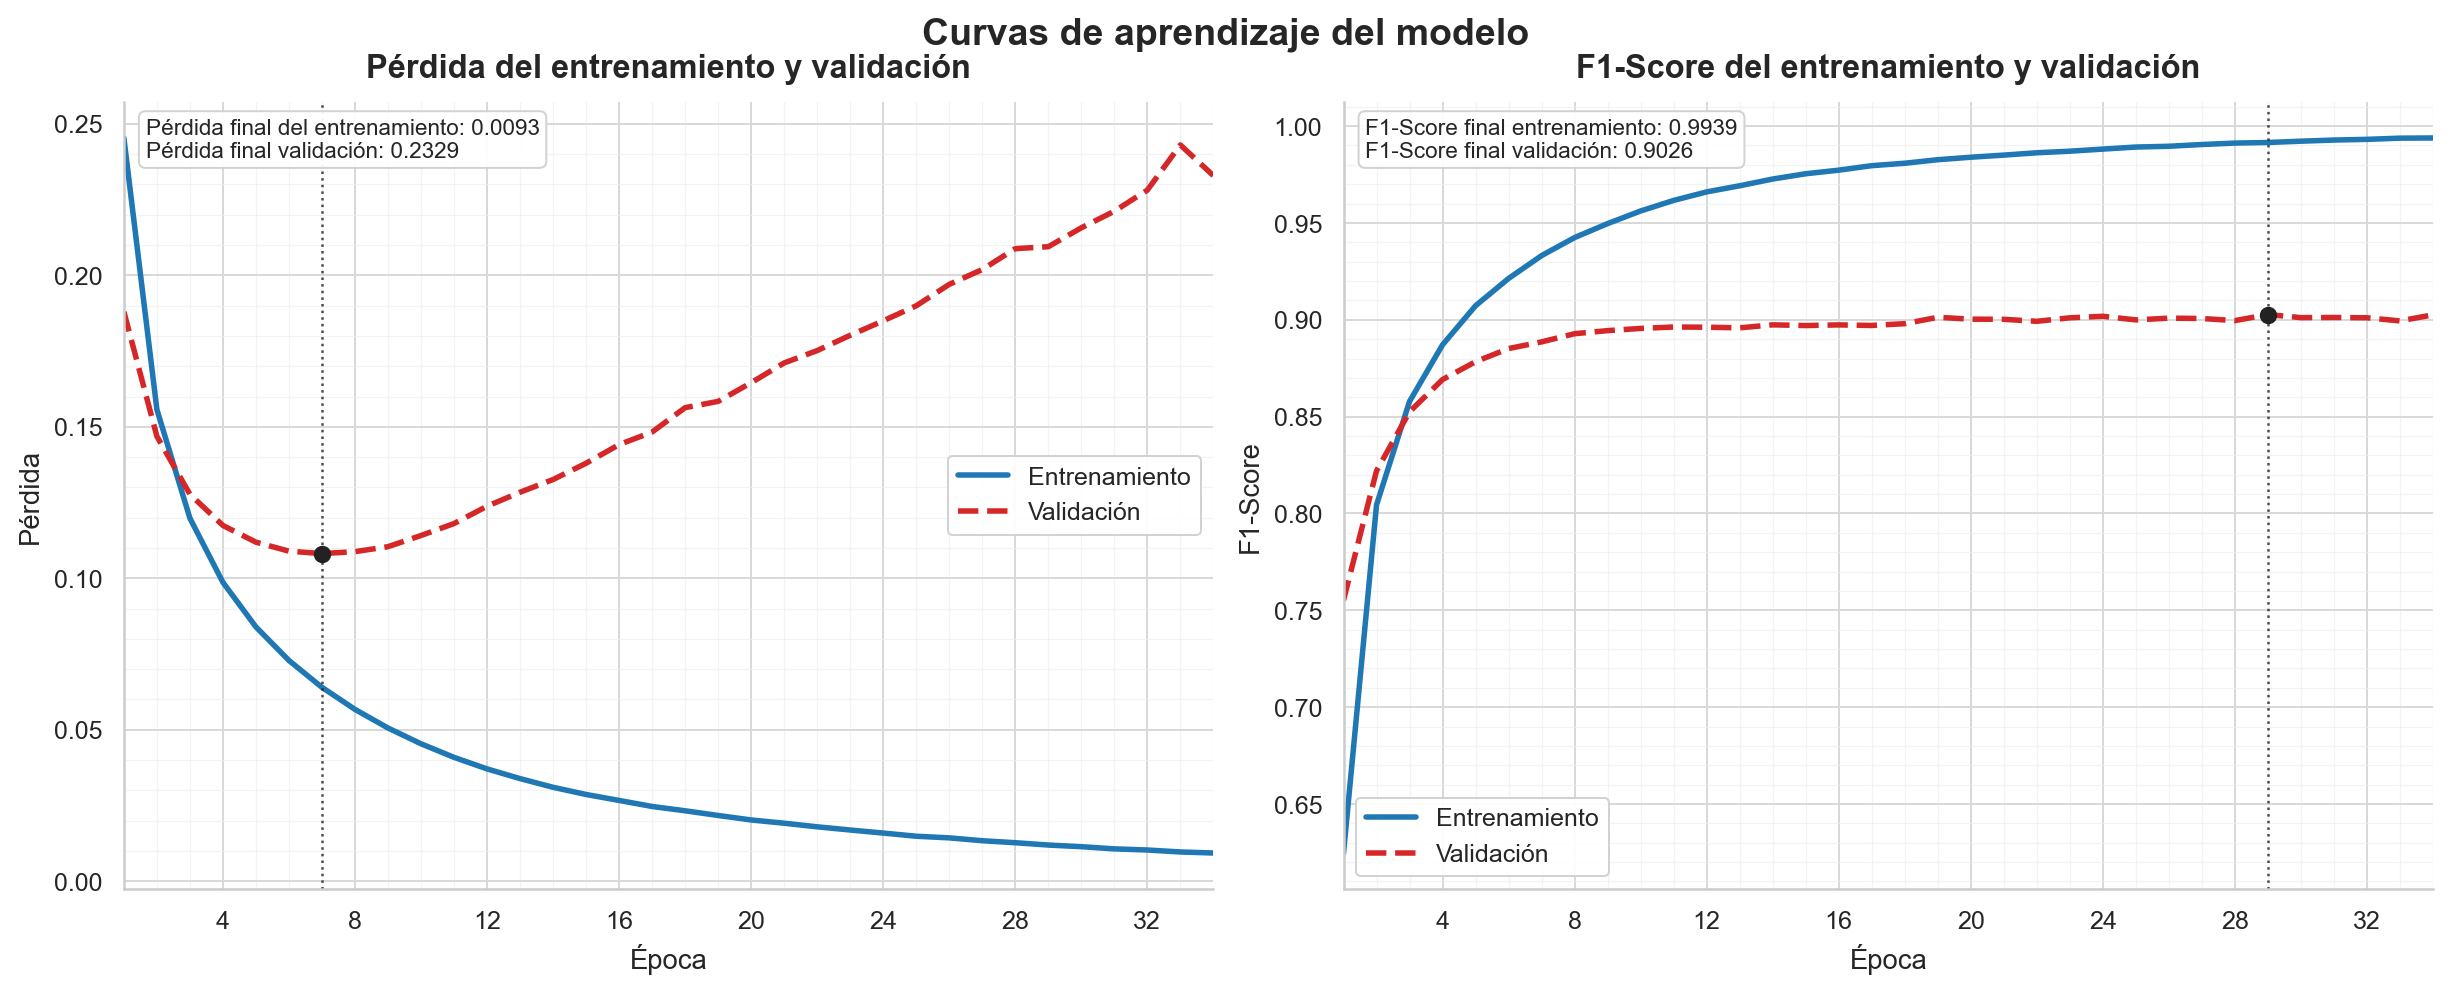

In [12]:
plot_charts(history, ('loss', 'f1_score'), ('Pérdida', 'F1-Score'))